# Session 5: A day-to-day as a bioinformatician

Clara, the research group’s principal investigator, has asked you to validate a
bacterial-genomics release in a collaboration effort with Tim's Lab at Boston. 

Tim's lab sent all the files back and Marc and Mike are waiting to continue downstream work. 
Before they receive the files to continue their work, Clara needs a clear answer:

> **Can this release be handed over safely? If not, under which limitations?**

Files opening successfully or matching transfer checksums is not enough. You will preserve
the supplied release, inspect its contract, collect evidence, identify material problems,
and write Clara a concise report with a handover recommendation.


You are going to apply all what we've seen over the last 4 sessions.


## How to work through Clara’s request

The workflow of this session follows one storyline:

`Receive → Inspect → Check → Compare & Validate → Interpret → Report → Hand Over`

Remember that you can consult documentation, the profesor, nearby colleagues about general approaches or an AI assistant (BUT DO NOT LET IT MAKE THE DECISIONS FOR YOU)


## Google Colab and local setup

Local Jupyter is the canonical route. Start it from the repository root,
`Module02_02/`, or `Module02_02/notebooks/`.

For Google Colab:

1. Copy the complete repository folder to Google Drive.
2. Run the optional installation cell once per fresh runtime.
3. Uncomment and run the Drive-mount cell.
4. Adjust `REPO_ROOT` only if your Drive folder differs from the example.

Outputs remain inside the Drive copy under `Module02_02/results/`.


In [13]:
# Google Colab only: uncomment and run once per fresh runtime.
# %pip install -q "biopython>=1.85,<2" "matplotlib>=3.9,<4" "numpy>=2,<3" "pandas>=2.2,<3" "pysam>=0.23,<0.24"


In [14]:
# Google Colab only: uncomment after copying the repository to Drive.
# from pathlib import Path
# from google.colab import drive
# drive.mount("/content/drive")
# REPO_ROOT = Path("/content/drive/MyDrive/UIC_Bioinformatics_-_AI_for_Healthcare")


In [15]:
#In this cellblock we just import the necessary libraries.
from __future__ import annotations
from collections import Counter
from datetime import date
from pathlib import Path
from urllib.parse import unquote
import gzip, hashlib, json, os, re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pysam
from Bio import SeqIO

#We set a column width for improved pandas display
pd.set_option("display.max_colwidth",100)


In [16]:
def find_module(start: Path, configured=None) -> Path:
    '''Locate Module02_02 from common local or Google Drive launch locations.'''
    start=Path(start).expanduser().resolve()
    places=([Path(configured).expanduser()] if configured is not None else [])+[start,*start.parents]
    for place in places:
        for candidate in (place,place/"Module02_02"):
            if candidate.name=="Module02_02" and (candidate/"data/capstone_blind").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Module02_02 was not found. Check your launch directory or REPO_ROOT.")

module_dir=find_module(Path.cwd(),globals().get("REPO_ROOT"))
data_dir=module_dir/"data/capstone_blind"
results_dir=(module_dir/"results").resolve()

STUDENT_ID="DFP_results"  # replace this placeholder with your own name or ID
if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_-]{1,31}",STUDENT_ID):
    raise ValueError("Use 2–32 letters, digits, underscores, or hyphens.")
results_dir.mkdir(parents=True,exist_ok=True)

def output_path(name: str) -> Path:
    if not re.fullmatch(r"[A-Za-z0-9_.-]+",name) or ".." in name:
        raise ValueError("Unsafe output filename")
    path=(results_dir/f"{STUDENT_ID}_{name}").resolve()
    if path.parent!=results_dir: raise ValueError("Output escaped results directory")
    return path

print("Release:",data_dir)
print("Your outputs:",results_dir)


Release: /home/smaug/Desktop/UIC_Bioinformatics_-_AI_for_Healthcare/Module02_02/data/capstone_blind
Your outputs: /home/smaug/Desktop/UIC_Bioinformatics_-_AI_for_Healthcare/Module02_02/results


## For this exercise we set a simple evidence documentation

Use two flat tables through pandas DataFrame:

- `metrics`: measured values and their declared expectations;
- `findings`: observations that require interpretation or action.

This keeps numbers separate from conclusions.


In [17]:
metrics=pd.DataFrame(columns=["file","metric","observed","expected","result"])
findings=pd.DataFrame(columns=["check","file","status","severity","evidence",
                               "consequence","action","limitation"])
consultations=pd.DataFrame(columns=["checkpoint","question","source","suggestion",
                                    "test","decision"])

# Across this practical hands on, you will use this two functions to add your own observations and metrics to the evidence tables.
# we are going to append our observations to the end of each of the dataframes.

def add_metric(file,metric,observed,expected,result):
    metrics.loc[len(metrics)]=[file,metric,observed,expected,result]

def add_finding(check,file,status,severity,evidence,consequence,action,limitation):
    findings.loc[len(findings)]=[check,file,status,severity,evidence,
                                 consequence,action,limitation]


# Our first question as a bioinformatician: what exactly arrived?

As the saying goes: Trust, but verify. It applies in all aspects of life, but even more so in bioinformatics.

Read the delivery note before touching the data. Then compare the directory with the
machine-readable manifest and checksum list.

Before running: **what can a checksum prove, and what can it never prove?**


In [18]:
readme=(data_dir/"README.md").read_text().splitlines()
print("\n".join(readme[:45]))
if len(readme)>45: print(f"[preview limited to 45 of {len(readme)} lines]")

# Read the manifest.json file and print some of its contents.
manifest=json.loads((data_dir/"manifest.json").read_text())
print("\nRelease identifier:",manifest["dataset"])
print("Declared reference:",manifest["reference"]["contig"],manifest["reference"]["length"],"bases")
print("Declared read pairs:",manifest["simulation"]["read_pairs"])
print("Declared variants:",manifest["simulation"]["variants"])


# Blinded bacterial release candidate

This directory contains a small bacterial genomics release candidate for the
Module02-02 hands-on practical. The reference and annotation were derived from
a public, complete bacterial genome. The organism identity is intentionally
withheld so that the practical focuses on file structure, validation, and
evidence-based release decisions.

The read and variant data are simulated and contain no patient or participant
information. Do not use sequence-similarity searches to identify the organism
during the exercise.

## Files

| File | Role |
|---|---|
| `reference.fasta` | Blinded circular reference sequence |
| `annotation.gff3` | De-identified reference annotation |
| `reads_R1.fastq.gz` / `reads_R2.fastq.gz` | Simulated paired-end reads |
| `alignments.sam` | Text alignment file |
| `alignments.bam` / `alignments.bam.bai` | Coordinate-sorted binary alignments and index |
| `variants.vcf` | Candidate small variants for `sample_A` |
| `targets.bed` 

In [19]:
#Set roles dictionary with all the expected files and their roles. 
roles={
 "README.md":"delivery note","manifest.json":"declared metrics",
 "checksums.sha256":"integrity list","reference.fasta":"reference",
 "reads_R1.fastq.gz":"forward reads","reads_R2.fastq.gz":"reverse reads",
 "alignments.sam":"text alignments","alignments.bam":"binary alignments",
 "alignments.bam.bai":"BAM index","variants.vcf":"candidate variants",
 "annotation.gff3":"annotation","targets.bed":"target intervals"}

checksum_lines=[]

# Read the checksums file and create a DataFrame with the expected SHA256 checksums for each file.
for line in (data_dir/"checksums.sha256").read_text().splitlines():
    digest,name=line.split(maxsplit=1)
    checksum_lines.append([name.lstrip("*"),digest])
checksum_list=pd.DataFrame(checksum_lines,columns=["file","expected_sha256"])

# Now we create a DataFrame with the inventory of files including role, suffix (file extension), size in bytes and whether it has checksum.
inventory=pd.DataFrame([
 {"file":path.name,"role":roles.get(path.name,"unexpected"),
  "suffix":"".join(path.suffixes) or "(none)","bytes":path.stat().st_size}
 for path in sorted(data_dir.iterdir()) if path.is_file()])
inventory["listed_for_checksum"]=inventory["file"].isin(checksum_list["file"])
inventory


,file,role,suffix,bytes,listed_for_checksum
0,README.md,delivery note,.md,2073,True
1,alignments.bam,binary alignments,.bam,2061796,True
2,alignments.bam.bai,BAM index,.bam.bai,1184,True
3,alignments.sam,text alignments,.sam,7206456,True
4,annotation.gff3,annotation,.gff3,242467,True
5,checksums.sha256,integrity list,.sha256,892,False
6,manifest.json,declared metrics,.json,698,True
7,reads_R1.fastq.gz,forward reads,.fastq.gz,1196827,True
8,reads_R2.fastq.gz,reverse reads,.fastq.gz,1196643,True
9,reference.fasta,reference,.fasta,588428,True


In [20]:
def sha256(path):
    """Compute the SHA256 digest of a file in a memory-efficient way (set chunk size to 1 MB)"""
    digest=hashlib.sha256()#This is a cryptographic hash function that produces a 256-bit(32 byte) hash value. Widely used to check integrity
    with Path(path).open("rb") as handle:
        # Lambda is a special operator that allows to create an anonymous function. In this case, read in chunks 
        for chunk in iter(lambda:handle.read(1024*1024),b""): digest.update(chunk)
    return digest.hexdigest()

#Now we compute the observed SHA256 checksums and compare it with our expected checksums from the checksums.sha256 file.
checksum_results=checksum_list.copy()
checksum_results["observed_sha256"]=[
    sha256(data_dir/name) if (data_dir/name).is_file() else "MISSING"
    for name in checksum_results["file"]]
checksum_results["matches"]=checksum_results["expected_sha256"]==checksum_results["observed_sha256"]

gzip_results=[]
#Now we check whether the compressed FASTQ files can be read in a streaming fashion (rb mode setting it to 1MB chunks)
for name in ["reads_R1.fastq.gz","reads_R2.fastq.gz"]:
    try:
        with gzip.open(data_dir/name,"rb") as handle:
            while handle.read(1024*1024): pass
        gzip_results.append([name,"PASS","stream readable"])
    except OSError as error:
        gzip_results.append([name,"FAIL",str(error)])
gzip_results=pd.DataFrame(gzip_results,columns=["file","status","evidence"])
missing=sorted(set(roles)-set(inventory["file"]))
unexpected=sorted(set(inventory["file"])-set(roles))
duplicate_checksum_names=checksum_list.loc[checksum_list["file"].duplicated(),"file"].tolist()
display(checksum_results[["file","matches"]]); display(gzip_results)

# I would add our findings here
add_metric("release","supplied files",len(inventory),len(roles),"PASS" if len(inventory)==len(roles) else "FAIL")
add_finding("intake","release","PASS" if not(missing or unexpected or duplicate_checksum_names) else "FAIL",
 "info" if not(missing or unexpected or duplicate_checksum_names) else "high",
 f"missing={missing}; unexpected={unexpected}; duplicate checksums={duplicate_checksum_names}",
 "An incomplete or ambiguous delivery cannot be reproduced.","Continue" if not missing else "Request a corrected delivery.",
 "Inventory does not assess biological correctness.")
add_finding("checksums","checksums.sha256","PASS" if checksum_results["matches"].all() else "FAIL",
 "info" if checksum_results["matches"].all() else "critical",
 f"{int(checksum_results['matches'].sum())}/{len(checksum_results)} digests match",
 "Corrupted bytes invalidate later checks.","Continue to content validation.","Integrity does not prove analytical validity.")


,file,matches
0,README.md,True
1,alignments.bam,True
2,alignments.bam.bai,True
3,alignments.sam,True
4,annotation.gff3,True
5,manifest.json,True
6,reads_R1.fastq.gz,True
7,reads_R2.fastq.gz,True
8,reference.fasta,True
9,targets.bed,True


,file,status,evidence
0,reads_R1.fastq.gz,PASS,stream readable
1,reads_R2.fastq.gz,PASS,stream readable


Equivalent if we wanted to check it through terminal reconnaissance from `Module02_02/`:

```bash
# GNU based workflow to identify and validate file integrity
find 'data/capstone_blind' -maxdepth 1 -type f -printf '%f\t%s bytes\n' | sort
(cd 'data/capstone_blind' && sha256sum -c checksums.sha256)
gzip -t 'data/capstone_blind/reads_R1.fastq.gz' 'data/capstone_blind/reads_R2.fastq.gz'
grep -c '^>' 'data/capstone_blind/reference.fasta'
gzip -cd 'data/capstone_blind/reads_R1.fastq.gz' | awk 'END {print NR, NR/4}'
gzip -cd 'data/capstone_blind/reads_R1.fastq.gz' | head -n 8
grep -vc '^#' 'data/capstone_blind/variants.vcf'
awk -F '\t' '$0 !~ /^#/ {n[$3]++} END {for(k in n) print k,n[k]}'   'data/capstone_blind/annotation.gff3' | sort
head -n 8 'data/capstone_blind/targets.bed'
grep '^@' 'data/capstone_blind/alignments.sam' | head
grep -v '^@' 'data/capstone_blind/alignments.sam' | head -n 3
if command -v samtools >/dev/null 2>&1; then
  samtools quickcheck 'data/capstone_blind/alignments.bam'
  samtools idxstats 'data/capstone_blind/alignments.bam'
fi
```

As you can see, to produce similar checks in python we had to generate more verbatim than some quick commands in bash. It is a matter of preference really, but I wanted to provide both ways of finding out.

However Clara still needs format-aware and cross-file evidence.


# Our second question as a bioinformatician: Is the coordinate system or rather, the biological integrity within each file trustworthy?

Great, we we are able to verify that the files that were originally shared were exactly what we have in our dataset. However... Do we know whether the integrity of the biological file is not compromised for downstream analysis?

The reference genome is the coordinate boundary shared by alignments, variants, annotation, and
targets. A quick QA would be checking its identifier, length, uniqueness, alphabet, GC fraction, and `N` count.


## 1st step: The reference genome
The reference genome is the coordinate boundary shared by alignments, variants, annotation, and
targets. A quick QA would be checking its identifier, length, uniqueness, alphabet, GC fraction, and `N` count.


In [21]:
# Let's start by parsing our reference genome
reference_records=list(SeqIO.parse(data_dir/"reference.fasta","fasta"))
# Generate basic metrics for each reference record.
reference_table=pd.DataFrame([
 {"id":record.id,"length":len(record.seq),
  "unexpected_symbols":"".join(sorted(set(str(record.seq).upper())-set("ACGTN"))),
  "GC_percent":round(100*(str(record.seq).upper().count("G")+str(record.seq).upper().count("C"))/len(record.seq),2),
  "N_count":str(record.seq).upper().count("N")}
 for record in reference_records])
reference={record.id:str(record.seq).upper() for record in reference_records}
reference_table


,id,length,unexpected_symbols,GC_percent,N_count
0,ref_01,580076,,31.69,0


In [22]:
# Now that we've got our reference_table parsed by ourselves, we can check whether the reference genome is consistent with the manifest
declared_id=manifest["reference"]["contig"]; declared_length=manifest["reference"]["length"]
# Check if the reference genome matches the declared metadata record by record based on ID, length and unexpected symbols: commmon pitfalls.
reference_ok=(len(reference_table)==1 and reference_table["id"].is_unique and
 reference_table.iloc[0]["id"]==declared_id and reference_table.iloc[0]["length"]==declared_length and
 reference_table.iloc[0]["unexpected_symbols"]=="" and reference_table.iloc[0]["length"]>0)

# Now we add the metrics and findings for the reference genome to our evidence tables. 
for metric_name,observed,expected in [
 ("record count",len(reference_table),1),("reference ID",reference_table.iloc[0]["id"],declared_id),
 ("reference length",reference_table.iloc[0]["length"],declared_length)]:
    add_metric("reference.fasta",metric_name,observed,expected,"PASS" if observed==expected else "FAIL")
add_finding("reference","reference.fasta","PASS" if reference_ok else "FAIL",
 "info" if reference_ok else "critical",reference_table.to_string(index=False),
 "Every coordinate-based file depends on this reference.","Use it as the common boundary." if reference_ok else "Stop and reconcile the reference.",
 "Length and alphabet do not prove provenance.")


## 2nd step: Do the read files behave like one paired experiment?

Clara needs evidence that both compressed FASTQ files parse, contain the declared number
of reads, use compatible mate names, and carry usable sequences and qualities.


### Guided theory application: one biological read, two mate names

Paired reads have a speciall suffix either  `/1` or `/2`. 

We need to create a function that removes a final `/1` or `/2`, leave a shared unsuffixed name
unchanged, and reject another slash-number suffix rather than guessing.

Quick Failure Testing: `sample/1`, `sample/2`, `sample`, and invalid `sample/3`.

In [23]:
def read_key(name: str) -> str:
    '''Return the shared read identifier for supported mate-name conventions.'''
    token=name.strip().split()[0]
    # We remove as /1 or /2 and return the unsuffixed name. [:-2] means we take all characters of the string except the last two.
    if token.endswith(("/1","/2")): return token[:-2]
    #We use re module (regular expression) to check for unsupported mate suffixes. We set it up AFTER the /1 and /2 check.
    # We scape the backward slash, then check for a digit (or more) at the end. This would match for example sample/3, sample/4..
    if re.search(r"/\d+$",token): raise ValueError(f"Unsupported mate suffix: {token}")
    return token


# Here we failure test the read key function before implementing it to the main workflow.
assert read_key("sample/1")==read_key("sample/2")=="sample"
assert read_key("sample")=="sample"
try:
    read_key("sample/3")
except ValueError as error:
    assert "Unsupported mate suffix" in str(error)
else:
    raise AssertionError("sample/3 should be rejected")


In [24]:
# Globals are the collection of global variables at the top of the script level.
if "read_key" not in globals():
    raise RuntimeError("Run the read_key helper first.")

# Now we parse with SeqIO the compressed fastq. Rt mode is used to read the file as text. Gzip used as it is compressed.
with gzip.open(data_dir/"reads_R1.fastq.gz","rt") as handle:
    reads_r1=list(SeqIO.parse(handle,"fastq"))
with gzip.open(data_dir/"reads_R2.fastq.gz","rt") as handle:
    reads_r2=list(SeqIO.parse(handle,"fastq"))

r1_keys=[read_key(record.description) for record in reads_r1]
r2_keys=[read_key(record.description) for record in reads_r2]

#Quick function to generate a row of metrics for a FASTQ file.
def fastq_row(label: str, records: list, keys: list) -> list:
    """Generate a row of metrics for a FASTQ file.
    label: a string label for the row
    records: a list of SeqRecord objects representing the reads
    keys: a list of read keys corresponding to the records"""
    lengths=[len(record.seq) for record in records]
    qualities=[q for record in records for q in record.letter_annotations["phred_quality"]]
    invalid=sum(bool(set(str(record.seq).upper())-set("ACGTN")) for record in records)
    return [label,len(records),len(set(keys)),len(records)-len(set(keys)),
            min(lengths),max(lengths),round(float(np.mean(qualities)),2),
            int(np.median(qualities)),invalid]
# Store it as a DataFrame.
fastq_table=pd.DataFrame(
 [fastq_row("R1",reads_r1,r1_keys),fastq_row("R2",reads_r2,r2_keys)],
 columns=["mate","records","unique IDs","duplicate IDs","min length","max length",
          "mean quality","median quality","reads with invalid symbols"])
fastq_table["mate names agree"]=[r1_keys==r2_keys,r1_keys==r2_keys]
fastq_table


,mate,records,unique IDs,duplicate IDs,min length,max length,mean quality,median quality,reads with invalid symbols,mate names agree
0,R1,10000,10000,0,150,150,37.0,37,0,True
1,R2,10000,10000,0,150,150,37.0,37,0,True


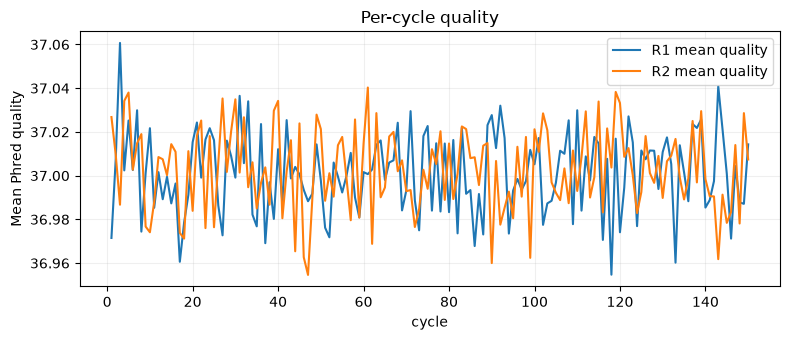

In [25]:
def quality_matrix(records: list) -> np.ndarray:
    """Return a 2D numpy array of Phred quality scores for a list of SeqRecord objects."""
    return np.asarray([record.letter_annotations["phred_quality"] for record in records])

q1=quality_matrix(reads_r1); q2=quality_matrix(reads_r2)

#We create a cycle dataframe so we can plot the R1 and R2 quality scores per sequencing cycle.
cycle_table=pd.DataFrame({"cycle":np.arange(1,q1.shape[1]+1),
                          "R1 mean quality":q1.mean(axis=0),
                          "R2 mean quality":q2.mean(axis=0)})
ax=cycle_table.plot(x="cycle",y=["R1 mean quality","R2 mean quality"],figsize=(8,3.5))
ax.set(ylabel="Mean Phred quality",title="Per-cycle quality"); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(output_path("fastq_per_cycle_quality.png"),dpi=160); plt.show()

declared_pairs=manifest["simulation"]["read_pairs"]; declared_length=manifest["simulation"]["read_length"]
fastq_ok=(len(reads_r1)==len(reads_r2)==declared_pairs and r1_keys==r2_keys and
 fastq_table["duplicate IDs"].eq(0).all() and fastq_table["min length"].eq(declared_length).all() and
 fastq_table["max length"].eq(declared_length).all() and
 fastq_table["reads with invalid symbols"].eq(0).all())

# Now add the metrics and findings. 
for row in fastq_table.itertuples(index=False):
    add_metric(f"reads_{row.mate}.fastq.gz","records",row.records,declared_pairs,
               "PASS" if row.records==declared_pairs else "FAIL")
add_finding("reads","reads_R1.fastq.gz; reads_R2.fastq.gz","PASS" if fastq_ok else "FAIL",
 "info" if fastq_ok else "high",fastq_table.to_string(index=False),
 "Read count, naming, length, or quality problems weaken downstream evidence.",
 "Continue to alignments." if fastq_ok else "Resolve FASTQ discrepancies first.",
 "Aggregate quality can hide local or library-specific bias.")


Write a two-sentence note for Clara int he markdown cell below: 
- One sentence describing what passed or failed.
- One stating what this FASTQ review still cannot establish.


## 3rd step: Do the alignments within the alignment.bam support the intended handover?

Are we sure the reads we are used as aligned to the correct reference genome? Or whether the reads used for the alignment are the ones we've just processed?


We can use the text SAM for transparent human inspection and BAM for format-aware, indexed access.


Keep in mind though that readability and valid coordinates answer a different question from whether mate-aware or insert-size analyses are possible downstream.


In [26]:
def scan_alignment(path: Path, mode: str) -> tuple[dict,set,list]:
    '''Return one flat row of alignment metrics and the normalized query IDs.'''
    counts=Counter(); mapq=[]; query_ids=set(); preview=[]
    # We take advantage of pysam to read the alignment file.
    with pysam.AlignmentFile(str(path),mode) as handle:
        header=handle.header.to_dict()#First store the header as a dict. It will allow us to access the header info structuredly
        header_refs="; ".join(f"{name}:{length}" for name,length in zip(handle.references,handle.lengths))#store the reference names.
        limits=dict(zip(handle.references,handle.lengths))
        #For each record we record the relevant metrics.
        for record in handle.fetch(until_eof=True):
            counts["total"]+=1
            counts["mapped"]+=int(not record.is_unmapped); counts["unmapped"]+=int(record.is_unmapped)
            counts["secondary"]+=int(record.is_secondary); counts["supplementary"]+=int(record.is_supplementary)
            counts["duplicate"]+=int(record.is_duplicate); counts["paired"]+=int(record.is_paired)
            counts["proper pair"]+=int(record.is_proper_pair); counts["read1"]+=int(record.is_read1)
            counts["read2"]+=int(record.is_read2); counts["mate reference"]+=int(record.next_reference_id>=0)
            counts["mate position"]+=int(record.next_reference_start>=0)
            #If the record is mapped, we store MAPQ, we check whether it missis CIGAR or whether is out bounds for record QA.
            if not record.is_unmapped:
                mapq.append(record.mapping_quality)
                counts["missing CIGAR"]+=int(record.cigarstring is None)
                counts["out of bounds"]+=int(record.reference_end is None or
                    record.reference_name not in limits or record.reference_end>limits.get(record.reference_name,0))
            if record.query_name: query_ids.add(read_key(record.query_name))
            if len(preview)<5: preview.append((record.query_name,record.flag,record.reference_name,
                                               record.reference_start,record.cigarstring))
    row={"file":Path(path).name,"references":header_refs,"sort order":header.get("HD",{}).get("SO",".")}
    for name in ["total","mapped","unmapped","secondary","supplementary","duplicate","paired",
                 "proper pair","read1","read2","mate reference","mate position","missing CIGAR","out of bounds"]:
        row[name]=counts[name]
    row["median MAPQ"]=float(np.median(mapq)) if mapq else np.nan
    return row,query_ids,preview

#Now we match SAM and BAM alignments and store the results.
sam_row,sam_ids,sam_preview=scan_alignment(data_dir/"alignments.sam","r")
bam_row,bam_ids,bam_preview=scan_alignment(data_dir/"alignments.bam","rb")
alignment_table=pd.DataFrame([sam_row,bam_row])
alignment_table


,file,references,sort order,total,mapped,unmapped,secondary,supplementary,duplicate,paired,proper pair,read1,read2,mate reference,mate position,missing CIGAR,out of bounds,median MAPQ
0,alignments.sam,ref_01:580076,coordinate,20000,20000,0,0,0,0,0,0,0,0,0,0,0,0,60.0
1,alignments.bam,ref_01:580076,coordinate,20000,20000,0,0,0,0,0,0,0,0,0,0,0,0,60.0


In [27]:
#We check whether the BAM index (.bam.bai) existis.
index_exists=(data_dir/"alignments.bam.bai").is_file()
index_works=False; index_message=""
try:
    with pysam.AlignmentFile(str(data_dir/"alignments.bam"),"rb") as bam:
        bam.check_index()#Internal method of pysam.
        first_contig=bam.references[0]
        #We fetch the first 1000 records from the first contig to check if the index works properly.
        indexed_records=sum(1 for _ in bam.fetch(first_contig,0,min(1000,bam.lengths[0])))
        index_works=True; index_message=f"indexed fetch returned {indexed_records} records"
except (ValueError,OSError) as error:
    # Relevant error message if index is messed up, as we will have to redo either the alignment or the index.
    index_message=str(error)

# Now compare with the expected data from the manifest and whether the alignments are suitable for mate-aware analyses.
expected_mapped=manifest["alignments"]["mapped_reads"]
coordinate_ok=(bam_row["mapped"]==expected_mapped and bam_row["out of bounds"]==0 and
 bam_row["missing CIGAR"]==0 and bam_row["sort order"]=="coordinate" and index_exists and index_works and
 sam_row["total"]==bam_row["total"] and sam_preview==bam_preview and sam_ids==bam_ids==set(r1_keys))
mate_aware_ok=(bam_row["paired"]==bam_row["total"] and bam_row["read1"]+bam_row["read2"]==bam_row["total"] and
 bam_row["mate reference"]==bam_row["total"] and bam_row["mate position"]==bam_row["total"])

add_metric("alignments.bam","mapped reads",bam_row["mapped"],expected_mapped,
           "PASS" if bam_row["mapped"]==expected_mapped else "FAIL")
add_metric("alignments.bam.bai","indexed access",index_message,"usable index",
           "PASS" if index_works else "FAIL")
add_finding("alignment coordinates","alignments.sam; alignments.bam; alignments.bam.bai",
 "PASS" if coordinate_ok else "FAIL","info" if coordinate_ok else "critical",
 f"SAM/BAM totals agree={sam_row['total']==bam_row['total']}; index={index_message}; FASTQ IDs agree={sam_ids==set(r1_keys)}",
 "Unreadable or coordinate-invalid alignments invalidate read-backed work.",
 "Assess mate metadata." if coordinate_ok else "Regenerate or reconcile alignments.",
 "Only five SAM/BAM records are compared field by field.")
add_finding("mate-aware suitability","alignments.sam; alignments.bam",
 "PASS" if mate_aware_ok else "FAIL","info" if mate_aware_ok else "high",
 alignment_table[["file","total","paired","proper pair","read1","read2","mate reference","mate position"]].to_string(index=False),
 "Mate-aware and insert-size analyses require pairing metadata.",
 "Continue" if mate_aware_ok else "Restrict use or regenerate alignments with mate metadata.",
 "Flags can be present yet biologically incorrect.")


Answer separately for Clara:

1. Are the alignments readable and coordinate-valid?
2. Are they suitable for analyses that depend on paired-read relationships?


## 4th step: Do the candidate variants agree with the reference?

Our collaborators passed a variant calling file already, so they have already been doing some downstream analysis themseleves. However, this does not proof that the VCF file matches our current dataset. We need to check it ourselves.


REMEMBER: The VCF `POS` field is 1-based, while Python sequence slices are 0-based. NEVER silently repair a REF mismatch, it might be a biological finding.


In [28]:
vcf_rows=[]; vcf_columns=None
# We parse the VCF file, which is a tab separated file which contain candidate variants.
for line_number,line in enumerate((data_dir/"variants.vcf").read_text().splitlines(),1):
    # We skip empty lines and comments. We move ahead to the Header line and the record lines
    if line.startswith("#CHROM"):
        vcf_columns=line.lstrip("#").split("\t")
    elif line and not line.startswith("#"):
        fields=line.split("\t")
        if len(fields)<8: raise ValueError(f"VCF line {line_number} has fewer than 8 fields")#REMEMBER this is a relevant  QA check
        vcf_rows.append([line_number,*fields])
if vcf_columns is None: raise ValueError("VCF #CHROM header is missing")#REMEMBER this is a relevant  QA check

#Now we store it as a DataFrame.
vcf=pd.DataFrame(vcf_rows,columns=["line",*vcf_columns])
vcf["POS"]=pd.to_numeric(vcf["POS"],errors="raise")

def variant_type(ref,alt):
    """For this specific exercise I've simplified the variant type classification for you"""
    if len(ref)==len(alt)==1: return "SNP"
    if len(alt)>len(ref): return "insertion"
    if len(ref)>len(alt): return "deletion"
    return "complex"


vcf["type"]=[variant_type(ref,alt) for ref,alt in zip(vcf["REF"],vcf["ALT"])]
vcf[["CHROM","POS","ID","REF","ALT","FILTER","type"]]


,CHROM,POS,ID,REF,ALT,FILTER,type
0,ref_01,44491,var_01,G,A,PASS,SNP
1,ref_01,81281,var_02,G,A,PASS,SNP
2,ref_01,119687,var_03,T,TCTG,PASS,insertion
3,ref_01,165271,var_04,A,T,PASS,SNP
4,ref_01,204855,var_05,GATC,G,PASS,deletion
5,ref_01,247840,var_06,C,A,PASS,SNP
6,ref_01,290966,var_07,G,C,PASS,SNP
7,ref_01,335375,var_08,A,AAT,PASS,insertion
8,ref_01,377816,var_09,G,A,PASS,SNP
9,ref_01,418615,var_10,GTG,G,PASS,deletion


In [29]:
# We use this simplified chek fucntion to check whether the REF field in the VCF files matches the reference genome.
def check_vcf_ref(row,reference):
    '''Return an empty string when REF agrees, otherwise a short error message.'''
    chrom=row["CHROM"]; pos=int(row["POS"]); ref=row["REF"]
    #chromosome, scaffold or contig is in the reference?
    if chrom not in reference: return "unknown contig"
    #Position MUST be positive and within the reference length
    if pos<1: return "POS must be positive"
    start0=pos-1#REMEMBER: Python based indexing starts at 0, while VCF file is 1-based!!!!!
    #We check if out of bounds for the reference.
    if start0+len(ref)>len(reference[chrom]): return "outside reference"
    observed=reference[chrom][start0:start0+len(ref)]
    return "" if observed==ref else f"REF mismatch: expected {ref}, observed {observed}"

#We set a quick set of Failure tests to check whether the function behaves as expected.
test_reference={"chrT":"ACGT"}
def test_row(chrom="chrT",pos=1,ref="A",alt="G"):
    return pd.Series({"CHROM":chrom,"POS":pos,"REF":ref,"ALT":alt})
assert check_vcf_ref(test_row(),test_reference)==""
assert check_vcf_ref(test_row(pos=2,ref="C",alt="CA"),test_reference)==""
assert check_vcf_ref(test_row(chrom="missing"),test_reference)=="unknown contig"
assert check_vcf_ref(test_row(pos=5),test_reference)=="outside reference"
assert check_vcf_ref(test_row(pos=2,ref="T"),test_reference).startswith("REF mismatch")
assert check_vcf_ref(test_row(pos=1,ref="A"),test_reference)==""


In [30]:
# Now we apply it to our real data from the VCF file.
vcf["reference check"]=[check_vcf_ref(row,reference) for _,row in vcf.iterrows()]
vcf_errors=vcf.loc[vcf["reference check"]!="",
                   ["line","CHROM","POS","ID","REF","ALT","reference check"]]
type_counts=vcf["type"].value_counts().rename_axis("type").reset_index(name="observed")
declared_types=pd.DataFrame([
 ["SNP",manifest["simulation"]["variant_types"]["SNP"]],
 ["insertion",manifest["simulation"]["variant_types"]["INS"]],
 ["deletion",manifest["simulation"]["variant_types"]["DEL"]]],
 columns=["type","expected"])
# We merge the types with the counts.
type_counts=declared_types.merge(type_counts,on="type",how="left").fillna({"observed":0})
display(vcf_errors); display(type_counts)

# We check with the declared variants from the manifest. 
declared_variants=manifest["simulation"]["variants"]
vcf_ok=(vcf_errors.empty and len(vcf)==declared_variants and
        type_counts["observed"].astype(int).equals(type_counts["expected"].astype(int)))

# We now add the metrics and findings if any.
add_metric("variants.vcf","records",len(vcf),declared_variants,
           "PASS" if len(vcf)==declared_variants else "FAIL")
add_finding("variants","variants.vcf","PASS" if vcf_ok else "FAIL",
 "info" if vcf_ok else "critical",
 f"records={len(vcf)}; reference errors={len(vcf_errors)}; types={dict(zip(type_counts['type'],type_counts['observed']))}",
 "Reference-inconsistent or undeclared variants can invalidate interpretation.",
 "Continue" if vcf_ok else "Request correction and rerun variant-dependent checks.",
 "This teaching check handles simple nucleotide alleles, not every VCF representation.")


,line,CHROM,POS,ID,REF,ALT,reference check
12,19,ref_01,550123,var_13,C,G,"REF mismatch: expected C, observed A"


,type,expected,observed
0,SNP,8,9
1,insertion,2,2
2,deletion,2,2


## 5th step: Does the annotation describe a coherent genome?

Clara does not need a production annotation framework, this might be what Marc and Mike are working on. 

What she ncurrently needs are transparent checks:
Nine fields, valid coordinates and strand/phase, unique IDs, resolvable parents, feature
counts, and bounds against the reference.


In [31]:
gff_rows=[]; malformed_gff=[]
# We parse the gff which as VCF is a tab separated file.
for line_number,line in enumerate((data_dir/"annotation.gff3").read_text().splitlines(),1):
    if not line or line.startswith("#"): continue # We skip the metadata lines 
    fields=line.split("\t")
    if len(fields)!=9:
        malformed_gff.append([line_number,f"expected 9 fields, observed {len(fields)}"])
        continue
    gff_rows.append([line_number,*fields])
# As before, we store it into a DataFrame object
gff=pd.DataFrame(gff_rows,columns=["line","seqid","source","type","start","end",
                                   "score","strand","phase","attributes"])
gff["start"]=pd.to_numeric(gff["start"],errors="raise")
gff["end"]=pd.to_numeric(gff["end"],errors="raise")

# A quick function to store the attributes
def attributes(text):
    result={}
    for item in text.split(";"):
        if not item: continue
        key,separator,value=item.partition("=")
        result[unquote(key)]=unquote(value) if separator else ""
    return result

# We remap every the attributes to the gff DataFrame
gff["attribute map"]=gff["attributes"].map(attributes)
gff["ID"]=gff["attribute map"].map(lambda item:item.get("ID",""))
gff["Parent"]=gff["attribute map"].map(lambda item:item.get("Parent",""))
feature_counts=gff["type"].value_counts().rename_axis("feature").reset_index(name="observed")
# We set the annotation feature counts from the manifest to check later.
declared_counts=pd.DataFrame(list(manifest["annotation_feature_counts"].items()),
                             columns=["feature","expected"])
feature_counts=declared_counts.merge(feature_counts,on="feature",how="outer").fillna(0)
feature_counts


,feature,expected,observed
0,CDS,524,524
1,RNase_P_RNA,1,1
2,SRP_RNA,1,1
3,exon,42,42
4,gene,546,546
5,pseudogene,20,20
6,rRNA,3,3
7,region,1,1
8,tRNA,36,36
9,tmRNA,1,1


In [32]:
# If we found gff errors, store them to then try to identify them efficiently
gff_problems=list(malformed_gff)
known_ids=set(gff.loc[gff["ID"]!="","ID"])
# ALWAYS check for duplicate IDs
duplicate_ids=set(gff.loc[(gff["ID"]!="") & gff["ID"].duplicated(keep=False),"ID"])
# Let's check gff for common issues.
for row in gff.itertuples(index=False):
    problem=[]
    if row.start<1 or row.end<row.start: problem.append("invalid 1-based interval")
    if row.seqid not in reference: problem.append("unknown seqid")
    elif row.end>len(reference[row.seqid]): problem.append("outside reference")
    if row.strand not in {"+","-",".","?"}: problem.append("invalid strand")
    if row.phase not in {"0","1","2","."}: problem.append("invalid phase")
    if row.ID in duplicate_ids: problem.append("duplicate ID")
    for parent in row.Parent.split(","):
        if parent and parent not in known_ids: problem.append(f"missing Parent {parent}")
    if problem: gff_problems.append([row.line,"; ".join(problem)])

# Now we define gff_errors as a DataFrame
gff_errors=pd.DataFrame(gff_problems,columns=["line","problem"])
counts_match=(feature_counts["observed"].astype(int)==feature_counts["expected"].astype(int)).all()
gff_ok=gff_errors.empty and counts_match
display(gff_errors); display(feature_counts)

# We add our metrics and findings if any.
add_metric("annotation.gff3","features",len(gff),int(feature_counts["expected"].sum()),
           "PASS" if len(gff)==int(feature_counts["expected"].sum()) else "FAIL")
add_finding("annotation","annotation.gff3","PASS" if gff_ok else "FAIL",
 "info" if gff_ok else "high",
 f"problems={len(gff_errors)}; maximum coordinate={gff['end'].max()}; counts match={counts_match}",
 "Broken coordinates or hierarchy can misassign genes and variant effects.",
 "Continue" if gff_ok else "Correct the annotation and rerun dependent checks.",
 "Structural consistency does not prove biological completeness.")


,line,problem


,feature,expected,observed
0,CDS,524,524
1,RNase_P_RNA,1,1
2,SRP_RNA,1,1
3,exon,42,42
4,gene,546,546
5,pseudogene,20,20
6,rRNA,3,3
7,region,1,1
8,tRNA,36,36
9,tmRNA,1,1


Why can a GFF3 file pass these checks and still be biologically incomplete?


## 6th step: Do the target intervals capture the candidate sites?

Okay, we validated the candidate variants, but we also got BED interval coordiantes. Are we sure those interval coordiantes capture the variant candidates' sites?

REMEMBER: BED uses 0-based, half-open coordinates. Therefore `end` must be greater than `start`,
and an interval ending at `x` does not overlap an interval beginning at `x`.


In [33]:
bed_rows=[]
# We open the BED file, which is another tab separted file
for line_number,line in enumerate((data_dir/"targets.bed").read_text().splitlines(),1):
    if not line or line.startswith(("#","track","browser")): continue#skip metadata lines
    fields=line.split("\t")# We split the line into a list by separator
    if len(fields)<3:
        bed_rows.append([line_number,"",np.nan,np.nan,"","fewer than 3 fields"])# Important QA check: minimum 3 fields.
        continue
    bed_rows.append([line_number,fields[0],fields[1],fields[2],
                     fields[3] if len(fields)>3 else "",""])
bed=pd.DataFrame(bed_rows,columns=["line","chrom","start","end","ID","load problem"])
bed


,line,chrom,start,end,ID,load problem
0,2,ref_01,44390,44591,target_01,
1,3,ref_01,81180,81381,target_02,
2,4,ref_01,119586,119787,target_03,
3,5,ref_01,165170,165371,target_04,
4,6,ref_01,204754,204958,target_05,
5,7,ref_01,247739,247940,target_06,
6,8,ref_01,290865,291066,target_07,
7,9,ref_01,335274,335475,target_08,
8,10,ref_01,377715,377916,target_09,
9,11,ref_01,418514,418717,target_10,


In [34]:
# We use this quick error reporting function for BED files.
def bed_problem(row,reference):
    '''Return an empty string for a valid BED row, otherwise a short reason.'''
    try: start,end=int(row["start"]),int(row["end"])#make sure the coordinates are ints not str, float or other type
    except (TypeError,ValueError): return "coordinates are not integers"
    # Common QA assignments
    if start<0: return "negative start"
    if end<=start: return "end must be greater than start"
    if row["chrom"] not in reference: return "unknown contig"
    if end>len(reference[row["chrom"]]): return "outside reference"
    if not row["ID"]: return "missing ID"
    return ""

# Set some Failure tests and assertions to check whether the function 
test_ref={"chrT":"A"*10}
def bed_test(chrom="chrT",start=2,end=5,ID="target"):
    return pd.Series({"chrom":chrom,"start":start,"end":end,"ID":ID})
assert bed_problem(bed_test(),test_ref)==""
assert bed_problem(bed_test(start=5,end=5),test_ref)=="end must be greater than start"
assert bed_problem(bed_test(start=-1),test_ref)=="negative start"
assert bed_problem(bed_test(start=8,end=10),test_ref)==""
assert bed_problem(bed_test(start=8,end=11),test_ref)=="outside reference"
assert bed_problem(bed_test(chrom="missing"),test_ref)=="unknown contig"


In [35]:
bed["problem"]=[
    load_problem or bed_problem(row,reference)
    for load_problem,(_,row) in zip(bed["load problem"],bed.iterrows())]
bed_errors=bed.loc[bed["problem"]!="",["line","chrom","start","end","ID","problem"]]

# Quick overlap helper function
def overlaps(a_start,a_end,b_start,b_end):
    return a_start<b_end and b_start<a_end
assert not overlaps(0,5,5,9)

# Check for overlaps between candidate variants (VCF) and the BED intervals.
overlaps_found=[]
for _,variant in vcf.iterrows():
    variant_start=int(variant["POS"])-1
    variant_end=variant_start+len(variant["REF"])
    for _,target in bed.loc[bed["problem"]==""].iterrows():
        if variant["CHROM"]==target["chrom"] and overlaps(
            variant_start,variant_end,int(target["start"]),int(target["end"])):
            overlaps_found.append([variant["ID"],variant_start,variant_end,target["ID"]])
overlap_table=pd.DataFrame(overlaps_found,
                            columns=["variant","variant start","variant end","target"])
display(bed_errors); display(overlap_table)

bed_ok=bed_errors.empty

# As always collect the metrics and add findings if any.
add_metric("targets.bed","records",len(bed),"valid rows",f"{len(bed)-len(bed_errors)} valid")
add_finding("targets","targets.bed","PASS" if bed_ok else "FAIL",
 "info" if bed_ok else "high",bed_errors.to_string(index=False) if not bed_ok else f"{len(bed)} valid intervals",
 "Invalid intervals can omit or misassign candidate variants.",
 "Continue" if bed_ok else "Correct targets and rerun overlap checks.",
 "Coordinate validity does not prove biological relevance.")
add_metric("variants.vcf + targets.bed","overlaps",len(overlap_table),"review against contract","RECORDED")


,line,chrom,start,end,ID,problem
12,14,ref_01,530000,530000,target_13,end must be greater than start


,variant,variant start,variant end,target
0,var_01,44490,44491,target_01
1,var_02,81280,81281,target_02
2,var_03,119686,119687,target_03
3,var_04,165270,165271,target_04
4,var_05,204854,204858,target_05
5,var_06,247839,247840,target_06
6,var_07,290965,290966,target_07
7,var_08,335374,335375,target_08
8,var_09,377815,377816,target_09
9,var_10,418614,418617,target_10


# Record how you asked for help

Choose one small helper from this notebook. If you used an AI assistant, your prompt should
state the input, coordinate convention, expected output, no silent repair, and tests.
Record what you accepted, corrected, or rejected.


In [36]:
consultations.loc[len(consultations)]=[
 "reads","Which mate-name endings are safe?","documentation",
 "Support /1 and /2; reject unknown slash-number endings",
 "tested /1, /2, no suffix, and /3","accepted after adding explicit rejection"]
consultations.loc[len(consultations)]=[
 "variants","How should VCF POS index FASTA?","course resource",
 "Use start0 = POS - 1","tested first base, bounds, and mismatch",
 "accepted after tests"]
ai_use={
 "task":"normalize a supported FASTQ mate name",
 "prompt":"Return the shared ID for /1 and /2; preserve unsuffixed names; reject another slash-number suffix; include tests.",
 "candidate":"read_key(name)",
 "tests":"/1, /2, no suffix, and invalid /3",
 "result":"valid cases passed; /3 raised ValueError",
 "decision":"correct then accept",
 "limitation":"supplier-specific conventions need additional examples"}


# Turn the evidence into Clara’s report

Review the flat tables. A count is not automatically a finding, and a failed check is not
automatically release-blocking. Consequence depends on intended downstream use.


In [37]:
display(metrics)
severity_order={"critical":0,"high":1,"medium":2,"low":3,"info":4}
material=findings.loc[findings["status"].isin(["FAIL","WARN"])].copy()
if not material.empty:
    material["_order"]=material["severity"].map(severity_order)
    material=material.sort_values(["_order","file"]).drop(columns="_order")
display(material)


,file,metric,observed,expected,result
0,release,supplied files,12,12,PASS
1,reference.fasta,record count,1,1,PASS
2,reference.fasta,reference ID,ref_01,ref_01,PASS
3,reference.fasta,reference length,580076,580076,PASS
4,reads_R1.fastq.gz,records,10000,10000,PASS
5,reads_R2.fastq.gz,records,10000,10000,PASS
6,alignments.bam,mapped reads,20000,20000,PASS
7,alignments.bam.bai,indexed access,indexed fetch returned 28 records,usable index,PASS
8,variants.vcf,records,13,12,FAIL
9,annotation.gff3,features,1175,1175,PASS


,check,file,status,severity,evidence,consequence,action,limitation
6,variants,variants.vcf,FAIL,critical,"records=13; reference errors=1; types={'SNP': 9, 'insertion': 2, 'deletion': 2}",Reference-inconsistent or undeclared variants can invalidate interpretation.,Request correction and rerun variant-dependent checks.,"This teaching check handles simple nucleotide alleles, not every VCF representation."
5,mate-aware suitability,alignments.sam; alignments.bam,FAIL,high,file total paired proper pair read1 read2 mate reference mate position\nalignme...,Mate-aware and insert-size analyses require pairing metadata.,Restrict use or regenerate alignments with mate metadata.,Flags can be present yet biologically incorrect.
8,targets,targets.bed,FAIL,high,line chrom start end ID problem\n 14 ref_01 530000 530000 ...,Invalid intervals can omit or misassign candidate variants.,Correct targets and rerun overlap checks.,Coordinate validity does not prove biological relevance.


The report must contain:

- recipient and purpose: Clara; intended handover to Marc and Mike;
- executive decision: PASS, PASS WITH WARNINGS, or FAIL;
- delivery received and integrity status;
- methods in plain language;
- evidence for reference/reads, alignments, variants, annotation, targets, and cross-file checks;
- material findings with consequence and action;
- required remediation and checks to rerun;
- limitations and consultation disclosure;
- explicit handover recommendation.

Use the code below.

In [38]:
blocking=not material.loc[(material["status"]=="FAIL") &
                           material["severity"].isin(["critical","high"])].empty
if blocking:
    DECISION="FAIL"; HANDOVER="be blocked until correction and revalidation"
elif not material.empty:
    DECISION="PASS WITH WARNINGS"; HANDOVER="proceed only with explicit restrictions"
else:
    DECISION="PASS"; HANDOVER="proceed"

def bullets(table,columns):
    if table.empty: return "- No material findings."
    return "\n".join("- "+"; ".join(f"{column}: {row[column]}" for column in columns)
                     for _,row in table.iterrows())

report=f'''# Release-validation report

## Recipient and purpose
- To: Clara, principal investigator
- Prepared by: {STUDENT_ID}
- Intended next recipients: Marc and Mike
- Release: {manifest["dataset"]}
- Date: {date.today().isoformat()}

## Executive decision
- Decision: **{DECISION}**
- Handover should **{HANDOVER}**.

## Delivery received
The delivery contained {len(inventory)} files. The inventory, checksum comparison, and
gzip checks are recorded in the exported tables. Transfer integrity was not treated as
analytical approval.

## Methods
I used bounded terminal reconnaissance, Biopython for FASTA/FASTQ, pysam for SAM/BAM and
indexed access, small transparent VCF/GFF3/BED checks, known-answer boundary tests, and
cross-file identifier and coordinate comparisons.

## Validation evidence
{bullets(findings,["check","file","status","evidence"])}

## Material findings
{bullets(material,["check","file","severity","evidence","consequence","action"])}

## Required remediation
Correct each material failure without overwriting the supplied release. Repeat the affected
format check, every dependent cross-file check, and this report before handover.

## Limitations
{bullets(findings,["check","limitation"])}

## AI and consultation disclosure
{bullets(consultations,["checkpoint","source","test","decision"])}
The AI-use record states the tested helper and its remaining limitation.

## Handover recommendation
The release should **{HANDOVER}** before Marc and Mike continue downstream work.
'''


In [39]:
inventory.to_csv(output_path("intake.tsv"),sep="\t",index=False)
metrics.to_csv(output_path("metrics.tsv"),sep="\t",index=False)
metrics.to_json(output_path("metrics.json"),orient="records",indent=2)
findings.to_csv(output_path("findings.tsv"),sep="\t",index=False)
consultations.to_csv(output_path("consultation_log.tsv"),sep="\t",index=False)
output_path("ai_use.md").write_text("# AI-use record\n\n"+
    "\n".join(f"- **{key}:** {value}" for key,value in ai_use.items())+"\n")
output_path("report.md").write_text(report)
print("Saved report and evidence under",results_dir)


Saved report and evidence under /home/smaug/Desktop/UIC_Bioinformatics_-_AI_for_Healthcare/Module02_02/results


# Before handover to Marc and Mike

Submit:

- completed notebook;
- intake TSV;
- metrics JSON and TSV;
- findings TSV;
- consultation log;
- AI-use record;
- FASTQ per-cycle quality plot;
- complete report to Clara.

Read the report once as if you were Marc or Mike. Does it say what can proceed, what cannot,
and why?


In [40]:
required=["intake.tsv","metrics.tsv","metrics.json","findings.tsv","consultation_log.tsv",
          "ai_use.md","fastq_per_cycle_quality.png","report.md"]
files=[output_path(name) for name in required]
missing_outputs=[path.name for path in files if not path.is_file()]
raw_unchanged=checksum_results["matches"].all() and all(
    sha256(data_dir/row.file)==row.expected_sha256 for row in checksum_list.itertuples())
print("Generated:")
print("\n".join(f"- {path.name}" for path in files if path.is_file()))
print("Missing:",missing_outputs or "none")
print("Supplied release still matches its checksums:",raw_unchanged)
print("The handover recommendation remains your responsibility.")


Generated:
- DFP_results_intake.tsv
- DFP_results_metrics.tsv
- DFP_results_metrics.json
- DFP_results_findings.tsv
- DFP_results_consultation_log.tsv
- DFP_results_ai_use.md
- DFP_results_fastq_per_cycle_quality.png
- DFP_results_report.md
Missing: none
Supplied release still matches its checksums: True
The handover recommendation remains your responsibility.
